# 04 · SLOCC classification with the N×6×6 ANN
**Paper:** Sec. III A (Fig. 1b), Sec. IV B, Table IV, Fig. 3  
Train on simulated states, validate on 18 and test on 12 of the 30 experimental states (100 random splits in the paper).  
**Code:** `ann_entanglement.models`, `ann_entanglement.experiments` (re-implementation — see PAPER_MAP.md)

In [1]:
import os, sys
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
sys.path.insert(0, os.path.abspath("../src"))  # not needed after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)

In [2]:
from ann_entanglement import experiments
train, exp_x = experiments.prepare(n_per_class=2000, seed=0)

Quick demo: the paper's optimal 6×6×6 model on 3 splits (≈20 s on CPU).

In [3]:
experiments.ann_sweep('slocc', train, exp_x, n_values=[6], n_splits=3)

I0000 00:00:1795434597.198823  781708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795434599.746435  781708 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


,N,network,features,mu_Av,sd_Av,mu_Lv,sd_Lv,mu_At,sd_At,mu_Lt,sd_Lt,A_T,sd_AT,acc_all30
0,6,6x6x6,"Re_rho_07, Re_rho_67, Re_rho_57, Re_rho_05, Re...",0.796,0.094,0.79,0.043,0.75,0.0,1.231,0.09,0.778,0.057,0.778


Full sweep over N = 1…18 from `scripts/reproduce_tables.py` (results/ holds a 10-split run; use `--splits 100` for the paper protocol).

,N,network,mu_Av,sd_Av,mu_Lv,sd_Lv,mu_At,sd_At,mu_Lt,sd_Lt,A_T,sd_AT,acc_all30,A1_svm,A2_knn
0,1,1x6x6,0.333,0.061,1.426,0.014,0.300,0.085,1.427,0.013,0.320,0.065,0.320,0.333,0.233
1,2,2x6x6,0.383,0.058,1.425,0.045,0.358,0.135,1.433,0.042,0.373,0.071,0.373,0.333,0.400
2,3,3x6x6,0.361,0.106,1.492,0.050,0.358,0.129,1.504,0.076,0.360,0.100,0.360,0.333,0.367
3,4,4x6x6,0.556,0.070,1.185,0.131,0.592,0.108,1.348,0.164,0.570,0.072,0.570,0.567,0.400
4,5,5x6x6,0.822,0.022,0.900,0.110,0.800,0.055,1.090,0.197,0.813,0.016,0.813,0.767,0.700
5,6,6x6x6,0.822,0.065,0.845,0.109,0.808,0.065,1.079,0.220,0.817,0.040,0.817,0.833,0.633
6,7,7x6x6,0.850,0.036,0.921,0.145,0.817,0.050,1.248,0.250,0.837,0.023,0.837,0.833,0.700
7,8,8x6x6,0.833,0.056,0.883,0.161,0.800,0.055,1.199,0.255,0.820,0.031,0.820,0.833,0.767
8,9,9x6x6,0.833,0.061,0.867,0.158,0.800,0.055,1.174,0.231,0.820,0.037,0.820,0.833,0.800
9,10,10x6x6,0.822,0.054,0.843,0.144,0.783,0.055,1.131,0.235,0.807,0.029,0.807,0.800,0.733


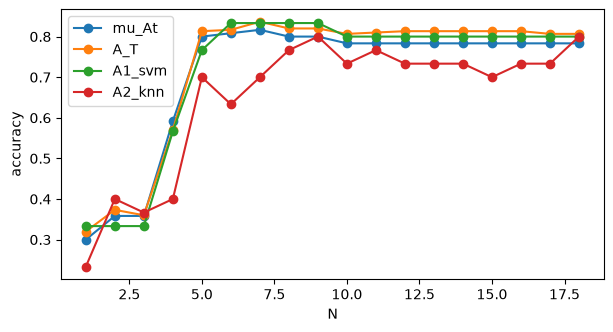

In [4]:
from pathlib import Path
p = sorted(Path('../results').glob('table4_slocc_ann_splits*.csv'))
if p:
    t4 = pd.read_csv(p[-1]); display(t4.drop(columns='features'))
    ax = t4.plot(x='N', y=['mu_At', 'A_T', 'A1_svm', 'A2_knn'], marker='o', figsize=(7, 3.5)); ax.set_ylabel('accuracy'); plt.show()
else:
    print('run scripts/reproduce_tables.py first')